# Time Series Analysis and Forecasting

A time series is any data indexed by time — monthly sales, daily temperatures, per-second server metrics. Time series differ from the tabular data used everywhere else in this roadmap in one decisive way: **the order carries information, and the future must never leak into the past.** That single rule changes how you validate, how you engineer features, and which models you can use.

> The worked example in this note uses the classic Box–Jenkins *international airline passengers* dataset (1949–1960, monthly totals in thousands) — public domain, and small enough to re-run in seconds.

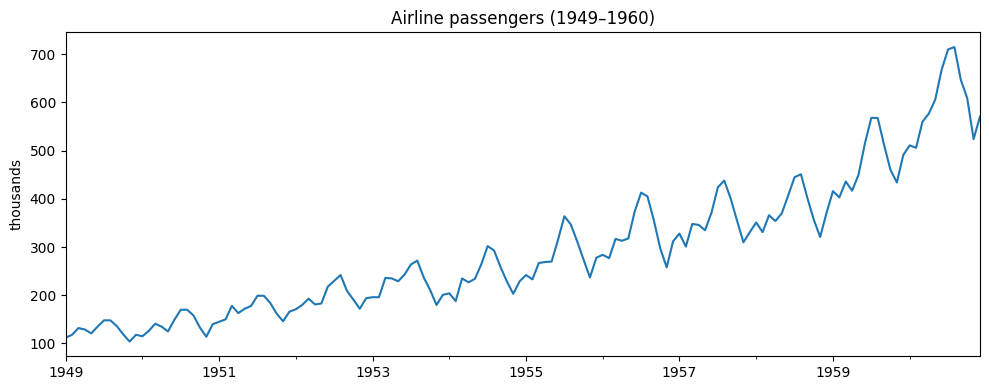

Observations: 144 | first: 112 | last: 571


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Box-Jenkins airline passengers: monthly totals (thousands), Jan 1949 - Dec 1960
values = [112,118,132,129,121,135,148,148,136,119,104,118,
          115,126,141,135,125,149,170,170,158,133,114,140,
          145,150,178,163,172,178,199,199,184,162,146,166,
          171,180,193,181,183,218,230,242,209,191,172,194,
          196,196,236,235,229,243,264,272,237,211,180,201,
          204,188,235,227,234,264,302,293,259,229,203,229,
          242,233,267,269,270,315,364,347,312,274,237,278,
          284,277,317,313,318,374,413,405,355,297,258,312,
          328,301,348,346,335,371,424,438,401,355,310,331,
          351,331,366,354,370,407,445,451,402,357,321,371,
          416,403,436,417,450,515,568,568,512,460,434,491,
          511,506,560,577,606,668,710,715,647,609,524,571]

ts = pd.Series(values,
               index=pd.date_range("1949-01", periods=len(values), freq="MS"),
               name="passengers")

plt.figure(figsize=(10, 4))
ts.plot()
plt.title("Airline passengers (1949–1960)")
plt.ylabel("thousands")
plt.tight_layout()
plt.show()

print("Observations:", len(ts), "| first:", ts.iloc[0], "| last:", ts.iloc[-1])

## 1. The Four Components

Most series decompose into:

| Component | What it is | Airline example |
|---|---|---|
| **Trend** | Long-run direction | Steady growth in air travel |
| **Seasonality** | Fixed-period repeat | Every July is peak travel season (period = 12) |
| **Cycle** | Irregular multi-year swing (no fixed period) | Business cycles |
| **Residual** | What's left — noise | Unexplained month-to-month wobble |

Additive model: $y_t = T_t + S_t + R_t$ (seasonal swing is constant).
Multiplicative model: $y_t = T_t \times S_t \times R_t$ (seasonal swing grows with the trend — the airline data is clearly like this, so we work with $\log y_t$).

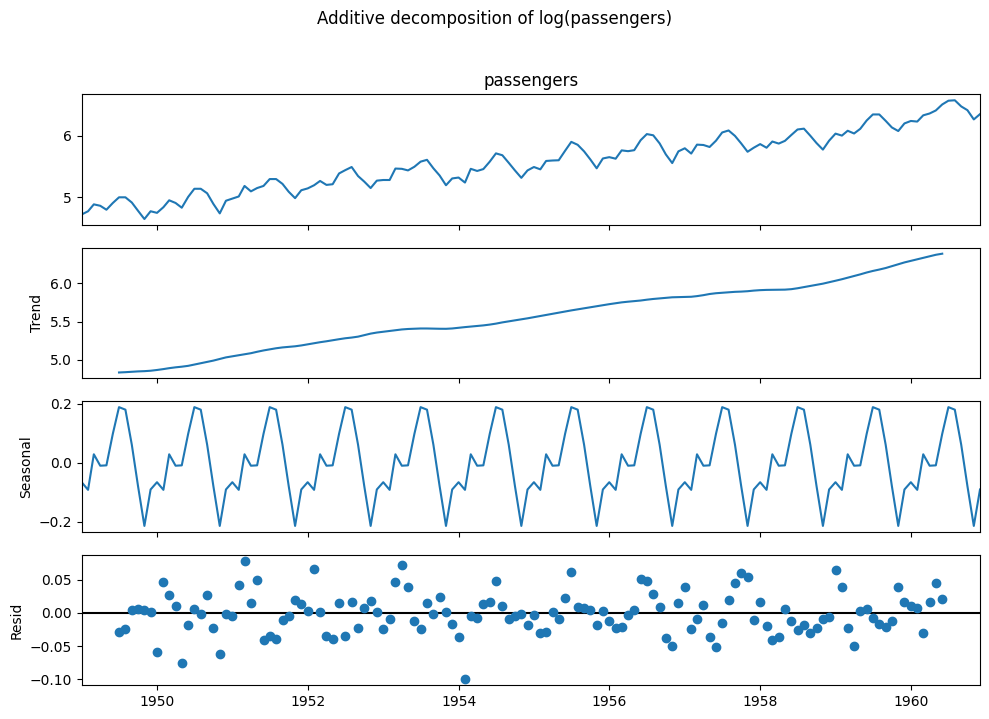

In [2]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Log transform turns the multiplicative pattern into an additive one
decomp = seasonal_decompose(np.log(ts), model="additive", period=12)

fig = decomp.plot()
fig.set_size_inches(10, 7)
fig.suptitle("Additive decomposition of log(passengers)", y=1.02)
plt.tight_layout()
plt.show()

## 2. Stationarity

A series is **stationary** when its statistical properties (mean, variance, autocorrelation) don't change over time. Classical ARIMA models assume it. Two common fixes:

- **Differencing** — model $y_t - y_{t-1}$ instead of $y_t$; seasonal differencing ($y_t - y_{t-12}$) removes yearly patterns.
- **Log transform** — stabilizes variance when the swings grow with the level.

The **Augmented Dickey-Fuller (ADF) test** checks stationarity: a small p-value (< 0.05) means you can reject "the series has a unit root" — i.e., it is stationary.

In [3]:
from statsmodels.tsa.stattools import adfuller

def adf_report(series, name):
    stat, pvalue, *_ = adfuller(series)
    verdict = "STATIONARY" if pvalue < 0.05 else "NON-stationary"
    print(f"{name:28s} ADF p = {pvalue:.4f}  ->  {verdict}")

adf_report(ts, "raw")
adf_report(np.log(ts), "log")
adf_report(np.log(ts).diff().dropna(), "log + 1st difference")
adf_report(np.log(ts).diff(12).dropna(), "log + seasonal diff (12)")

raw                          ADF p = 0.9984  ->  NON-stationary
log                          ADF p = 0.9714  ->  NON-stationary
log + 1st difference         ADF p = 0.1313  ->  NON-stationary
log + seasonal diff (12)     ADF p = 0.1226  ->  NON-stationary


> **Reading real-world p-values:** the p-value falls from 0.998 to ~0.12 after differencing — directionally right, but still above 0.05. Don't panic: on only 144 observations the ADF test has low statistical power, and the classical Box–Jenkins treatment of this exact dataset applies the $\log + (1-B)(1-B^{12})$ transformation and treats the result as stationary. In practice you decide with **both** the test *and* the ACF plot (next section), never a single number.

## 3. Autocorrelation: ACF and PACF

- **ACF** — correlation of the series with its own lags. Slow decay = trend; spikes at 12, 24, 36 = yearly seasonality.
- **PACF** — correlation at lag $k$ after removing the effect of the shorter lags.

Rules of thumb for choosing ARIMA orders on a stationary series:

| Pattern in | Suggests |
|---|---|
| PACF cuts off at lag $p$ | AR($p$) term |
| ACF cuts off at lag $q$ | MA($q$) term |
| Both tail off slowly | mixed ARMA |

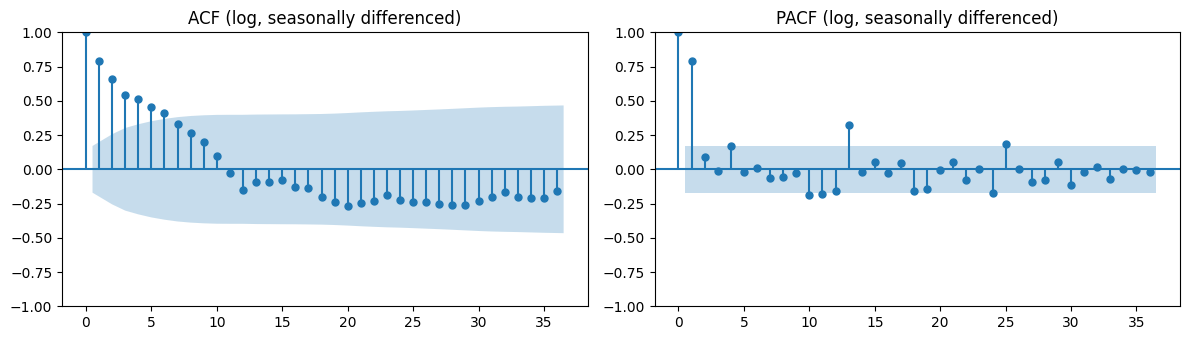

In [4]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(np.log(ts).diff(12).dropna(), lags=36, ax=axes[0], title="ACF (log, seasonally differenced)")
plot_pacf(np.log(ts).diff(12).dropna(), lags=36, ax=axes[1], method="ywm",
          title="PACF (log, seasonally differenced)")
plt.tight_layout()
plt.show()

## 4. The Model Families

| Family | Idea | When to use |
|---|---|---|
| **Naive / seasonal naive** | Last value, or last same-month value | The mandatory baseline — beat it or don't ship |
| **Exponential smoothing / Holt-Winters** | Weighted averages with level, trend, seasonal states | Strong classical baseline, few parameters |
| **ARIMA / SARIMA** | Regression on own lags + past forecast errors (with seasonal terms) | Small, well-understood series |
| **Gradient boosting + features** | LightGBM/XGBoost on lag, rolling, and calendar features | Many series or exogenous drivers (promotions, holidays) |
| **Global / deep models** | N-BEATS, DeepAR-style, and Transformer-based forecasters; LLM-era tools | Thousands of related series, enough history to learn across them |

**Forecasting ≠ ordinary supervised learning:** you cannot shuffle, you cannot sample validation randomly, and feature engineering must only look backwards. Review **Data Leakage (Level 3, Section 16)** — it is essentially a time-series section in disguise.

## 5. Validation: Walk Forward, Never Shuffle

Random K-fold CV is invalid for forecasting — a random fold will happily train on 2020 to "predict" 2019. The correct scheme is **expanding-window (walk-forward)** validation: train on the past, test on the next horizon, then roll forward.

In the walkthrough below we keep it simple: train on 1949–1958, forecast the 24 months of 1959–1960, and score with MAE / RMSE / MAPE (definitions in **Level 2, Section 7**).

In [5]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error

train, test = ts[:"1958"], ts["1959":]
log_train = np.log(train)

# --- Baseline: seasonal naive (last observed same-month value) ---
naive = train[-12:].values.tolist()
seasonal_naive = pd.Series([naive[i % 12] for i in range(len(test))], index=test.index)

# --- Holt-Winters (additive trend + seasonality on log scale) ---
hw_fit = ExponentialSmoothing(log_train, trend="add", seasonal="add",
                              seasonal_periods=12).fit()
hw = np.exp(hw_fit.forecast(len(test)))

# --- SARIMA: ARIMA(1,1,1) x (1,1,1,12) on log scale ---
with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # MLE may not fully converge on 120 points
    sarima_fit = ARIMA(log_train, order=(1, 1, 1),
                       seasonal_order=(1, 1, 1, 12)).fit()
sarima = np.exp(sarima_fit.forecast(len(test)))

def mape(y_true, y_pred):
    return 100 * np.mean(np.abs((y_true - y_pred) / y_true))

models = {"Seasonal naive": seasonal_naive, "Holt-Winters": hw, "SARIMA": sarima}
for name, pred in models.items():
    print(f"{name:14s} MAE={mean_absolute_error(test, pred):6.2f}  "
          f"RMSE={np.sqrt(np.mean((test - pred)**2)):6.2f}  MAPE={mape(test, pred):5.2f}%")

Seasonal naive MAE=159.25  RMSE=174.06  MAPE=28.52%
Holt-Winters   MAE= 74.96  RMSE= 85.85  MAPE=13.31%
SARIMA         MAE= 89.14  RMSE=100.24  MAPE=15.88%


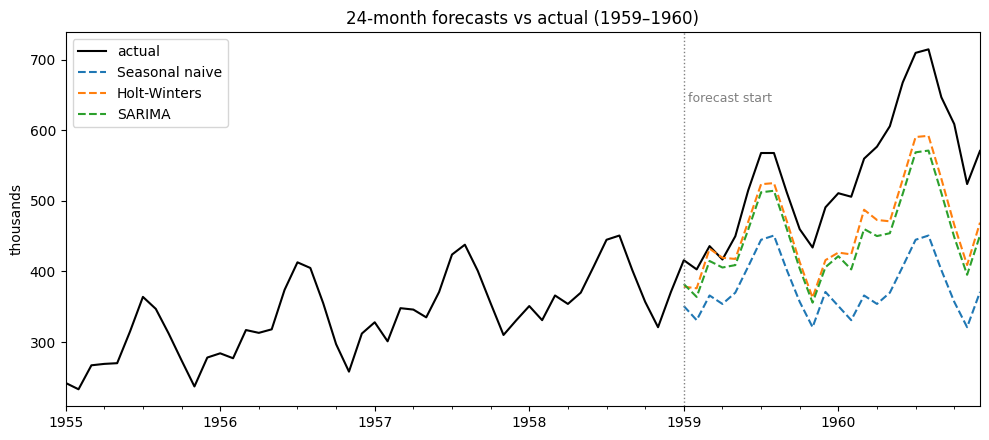

In [6]:
plt.figure(figsize=(10, 4.5))
ts["1955":].plot(label="actual", color="black", lw=1.5)
for name, pred in models.items():
    pred.plot(label=name, ls="--")
plt.axvline(test.index[0], color="gray", ls=":", lw=1)
plt.text(test.index[0], 640, " forecast start", color="gray", fontsize=9)
plt.title("24-month forecasts vs actual (1959–1960)")
plt.ylabel("thousands")
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
# Walk-forward validation: refit each year and forecast the next 12 months
from statsmodels.tsa.arima.model import ARIMA

fold_errors = []
for cutoff_year in range(1954, 1960):
    tr = ts[:f"{cutoff_year}"]
    te = ts[f"{cutoff_year+1}":f"{cutoff_year+1}"]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = ARIMA(np.log(tr), order=(1, 1, 1),
                    seasonal_order=(1, 1, 1, 12)).fit()
    pred = np.exp(fit.forecast(12))[:len(te)]
    fold_errors.append(mean_absolute_error(te[:len(pred)], pred))

print("Walk-forward MAE by fold:", [round(e, 1) for e in fold_errors])
print(f"Mean walk-forward MAE: {np.mean(fold_errors):.2f}")

Walk-forward MAE by fold: [np.float64(14.6), np.float64(6.7), np.float64(15.9), np.float64(25.1), np.float64(48.5), np.float64(25.1)]
Mean walk-forward MAE: 22.65


## 6. Key Takeaways

- **Never shuffle.** Use walk-forward / expanding-window validation; a random split inflates your metrics by peeking at the future.
- **Plot first**: trend, seasonality, and variance growth tell you whether to log-transform and difference *before* any model.
- **Always beat the seasonal-naive baseline** — it is embarrassingly hard to beat on monthly business data.
- On single small series, **Holt-Winters and SARIMA** remain excellent; with many related series or rich covariates, move to **gradient boosting with engineered lag features**, then global/deep forecasters.
- Feature engineering for time series = lags, rolling statistics, and calendar features — all computed with a horizon-aware cutoff.

**Resources to go deeper:**
- *Forecasting: Principles and Practice* (Hyndman & Athanasopoulos) — the standard textbook, [free online](https://otexts.com/fpp3/)
- [statsmodels time-series docs](https://www.statsmodels.org/stable/tsa.html) and [sktime](https://www.sktime.net/) for a scikit-learn-style API
- Kaggle's [Store Sales](https://www.kaggle.com/competitions/store-sales-time-series-forecasting) competition for guided practice